# 01 — Choose the box size for the RTENSO2026 year selection

Step 1 of the workflow:

| Step | Notebook | Uses |
| --- | --- | --- |
| 1. Box size | `01_choose_box_size.ipynb` (this) | BruteForce archive and observations only |
| 2. Year search and restarts | `02_build_climatology_ic.ipynb` | `BOX` from step 1 |
| 3. Climatology + observed anomaly | `03_build_clim_anomaly_ic.ipynb` | `clim` year from step 2 |
| 4. Evaluation | `04_evaluate_ic_metrics.ipynb`, `05_plot_mpassi_ic_mosaic.ipynb`, `06_plot_elm_ic_mosaic.ipynb` | actual 2015 restarts |

The `obs` branch compares model and observed standardized anomalies after averaging them over lat-lon
boxes of `BOX = (dlat, dlon)` degrees. The box size is chosen here **without the 2015 test dates**,
so the 2015 evaluation in step 4 stays independent of it.

## Leave-one-out test

For each calendar date (Feb, May, Aug, Nov 1) and each archive year $y$ (`FIRST_YEAR`-2018, as in 02):

1. Treat $y$ as the unknown target. The `obs` selection with box $b$ picks, from the other years, the
   year closest to the observed anomaly of $y$ (ERA5-Land for land, NOAA/NSIDC CDR for sea ice, the
   default observations).
2. Score the pick against the **actual model state of $y$** (`distance_to_model_year` metric):
   joint distance $D$ over the observable fields or all key fields (including sea-ice thickness and
   snow on ice, which have no observations).

**Decision rule.** The primary criterion is closeness on the **native model grid** (the full state
the model starts from): boxes whose skill there is within two standard errors of the best are tied.
Among the tied boxes, the one with the highest **large-scale** skill (both states averaged over
30x60 boxes before comparing) is chosen, since large-scale anomalies carry most of the seasonal
signal. Every box is judged at these same two scales; neither is the scale being chosen.

**Box-edge placement.** With a single box grid, the result depended on where the box edges happened
to fall (for example, 15x30 scored below both 10x20 and 20x40). With `BOX_SHIFTS = 4`, each box
size is also evaluated on grids shifted by half a box in latitude, in longitude, and in both, and the
selection distance is the RMS over the four placements. This removes the edge noise, raises the skill
of every box size, and is used in the selection itself (02, 03).

Skill of a pick: $(D_\mathrm{rms}-D_\mathrm{pick})/(D_\mathrm{rms}-D_\mathrm{best})$, with
$D_\mathrm{best}$ the closest candidate (skill 1) and $D_\mathrm{rms}$ the RMS over the candidates
(a random pick, skill about 0). Each month gives one test case per archive year (24 for 1995-2018).

Code: `util/box_loo.py`.

In [1]:
from pathlib import Path
import importlib
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("util").resolve()))
import box_loo
import clim_restart

clim_restart = importlib.reload(clim_restart)
box_loo = importlib.reload(box_loo)

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 250)
plt.rcParams["figure.dpi"] = 120

## Configuration

In [2]:
SRC_ROOT  = Path("/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/BruteForce")
OUT_ROOT  = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions")
CACHE_DIR = OUT_ROOT / "cache"          # model and observed key fields cached by 02
DIAG_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic")
SAVE_DIAG = True

# Observations used by the selection: ERA5-Land (land) + NOAA/NSIDC CDR (sea ice), the default
# obs_era5land_nsidc branch of 02. OBS_TAG names the result files.
OBS_DATA   = Path("/global/cfs/cdirs/e3sm/zhan391/data")
OBS_ROOT   = {"elm": OBS_DATA / "ERA5_LND", "mpassi": OBS_DATA / "NOAA_NSIDC"}
OBS_FIELDS = {"elm": ["sd", "swvl1", "swvl2-4", "stl1", "stl2-4"], "mpassi": ["ci"]}
OBS_TAG    = "era5land_nsidc"

MONTHS = ["02-01", "05-01", "08-01", "11-01"]
FIRST_YEAR = 1995                       # candidate years, as in 02
LAST_YEAR = None

BOXES = [None, (10, 20), (15, 30), (20, 40), (30, 60), (45, 90)]
# Placements of the box edges averaged in the selection distance (1, 2, or 4): with 4, each box
# size is also evaluated on grids shifted by half a box in lat, lon, and both, so the result
# does not hinge on where the edges fall. Use the same value as BOX_SHIFTS in 02 and 03.
BOX_SHIFTS = 4
SCORES = {"points": None, "30x60": (30, 60)}   # primary: model points; tie-breaker: 30x60 box means

RUN_TAG = OBS_TAG + ("" if BOX_SHIFTS == 1 else f"_shift{BOX_SHIFTS}")
RESULTS_CSV = DIAG_ROOT / "data" / f"box_size_loo_{RUN_TAG}.csv"
RECOMPUTE = False                       # True reruns the test (about 12 min, one process per month)

## 1. Run the leave-one-out test

Reads the cached key fields; one row per month, held-out year, and box.

In [3]:
if RESULTS_CSV.is_file() and not RECOMPUTE:
    loo = box_loo.add_skill(pd.read_csv(RESULTS_CSV, dtype={"month": str}))
    print(f"read {RESULTS_CSV}")
else:
    loo = box_loo.run_loo(MONTHS, src_root=SRC_ROOT, out_root=OUT_ROOT, cache_dir=CACHE_DIR,
                          first_year=FIRST_YEAR, last_year=LAST_YEAR, boxes=BOXES, scores=SCORES,
                          box_shifts=BOX_SHIFTS,
                          obs_root=OBS_ROOT, obs_fields=OBS_FIELDS)
    if SAVE_DIAG:
        RESULTS_CSV.parent.mkdir(parents=True, exist_ok=True)
        loo.to_csv(RESULTS_CSV, index=False)
        print(f"saved {RESULTS_CSV}")

LABELS = [box_loo.box_label(b) for b in BOXES]
KEYS = box_loo.score_keys(loo)
n_years = loo.groupby("month")["year"].nunique()
print(f"{len(loo)} rows; test years per month: {dict(n_years)}")

saved /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/data/box_size_loo_era5land_nsidc_shift4.csv
576 rows; test years per month: {'02-01': np.int64(24), '05-01': np.int64(24), '08-01': np.int64(24), '11-01': np.int64(24)}


## 2. Skill by box, month, and scoring scale

Mean skill (0 = random year, 1 = best possible year). `points,*` is the primary criterion (closeness
on the native grid), `30x60,*` the tie-breaker (closeness of 30x60 box means). `*,all` includes the
unobserved sea-ice thickness and snow on ice.

In [4]:
for key in KEYS:
    print(f"scored at {key}")
    display(box_loo.skill_table(loo, key, LABELS).style.format("{:.3f}").highlight_max(axis=0, color="#cde"))

scored at points,observable


month,02-01,05-01,08-01,11-01,all
box,,,,,
points,0.759,0.842,0.751,0.839,0.798
10x20,0.770,0.812,0.797,0.826,0.801
15x30,0.760,0.750,0.793,0.817,0.780
20x40,0.715,0.750,0.763,0.829,0.764
30x60,0.645,0.730,0.670,0.792,0.709
45x90,0.612,0.721,0.607,0.737,0.669


scored at points,all


month,02-01,05-01,08-01,11-01,all
box,,,,,
points,0.708,0.714,0.589,0.696,0.677
10x20,0.695,0.737,0.677,0.750,0.715
15x30,0.679,0.670,0.655,0.760,0.691
20x40,0.675,0.663,0.650,0.791,0.695
30x60,0.468,0.603,0.524,0.747,0.586
45x90,0.493,0.652,0.603,0.784,0.633


scored at 30x60,observable


month,02-01,05-01,08-01,11-01,all
box,,,,,
points,0.749,0.729,0.787,0.834,0.775
10x20,0.763,0.755,0.734,0.836,0.772
15x30,0.787,0.825,0.731,0.837,0.795
20x40,0.717,0.858,0.780,0.847,0.800
30x60,0.743,0.888,0.748,0.821,0.800
45x90,0.703,0.834,0.742,0.813,0.773


scored at 30x60,all


month,02-01,05-01,08-01,11-01,all
box,,,,,
points,0.675,0.675,0.582,0.676,0.652
10x20,0.678,0.707,0.575,0.743,0.676
15x30,0.732,0.694,0.576,0.758,0.690
20x40,0.643,0.707,0.556,0.785,0.673
30x60,0.574,0.725,0.478,0.747,0.631
45x90,0.592,0.729,0.603,0.786,0.678


saved /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/box_size_loo_skill_era5land_nsidc_shift4.png


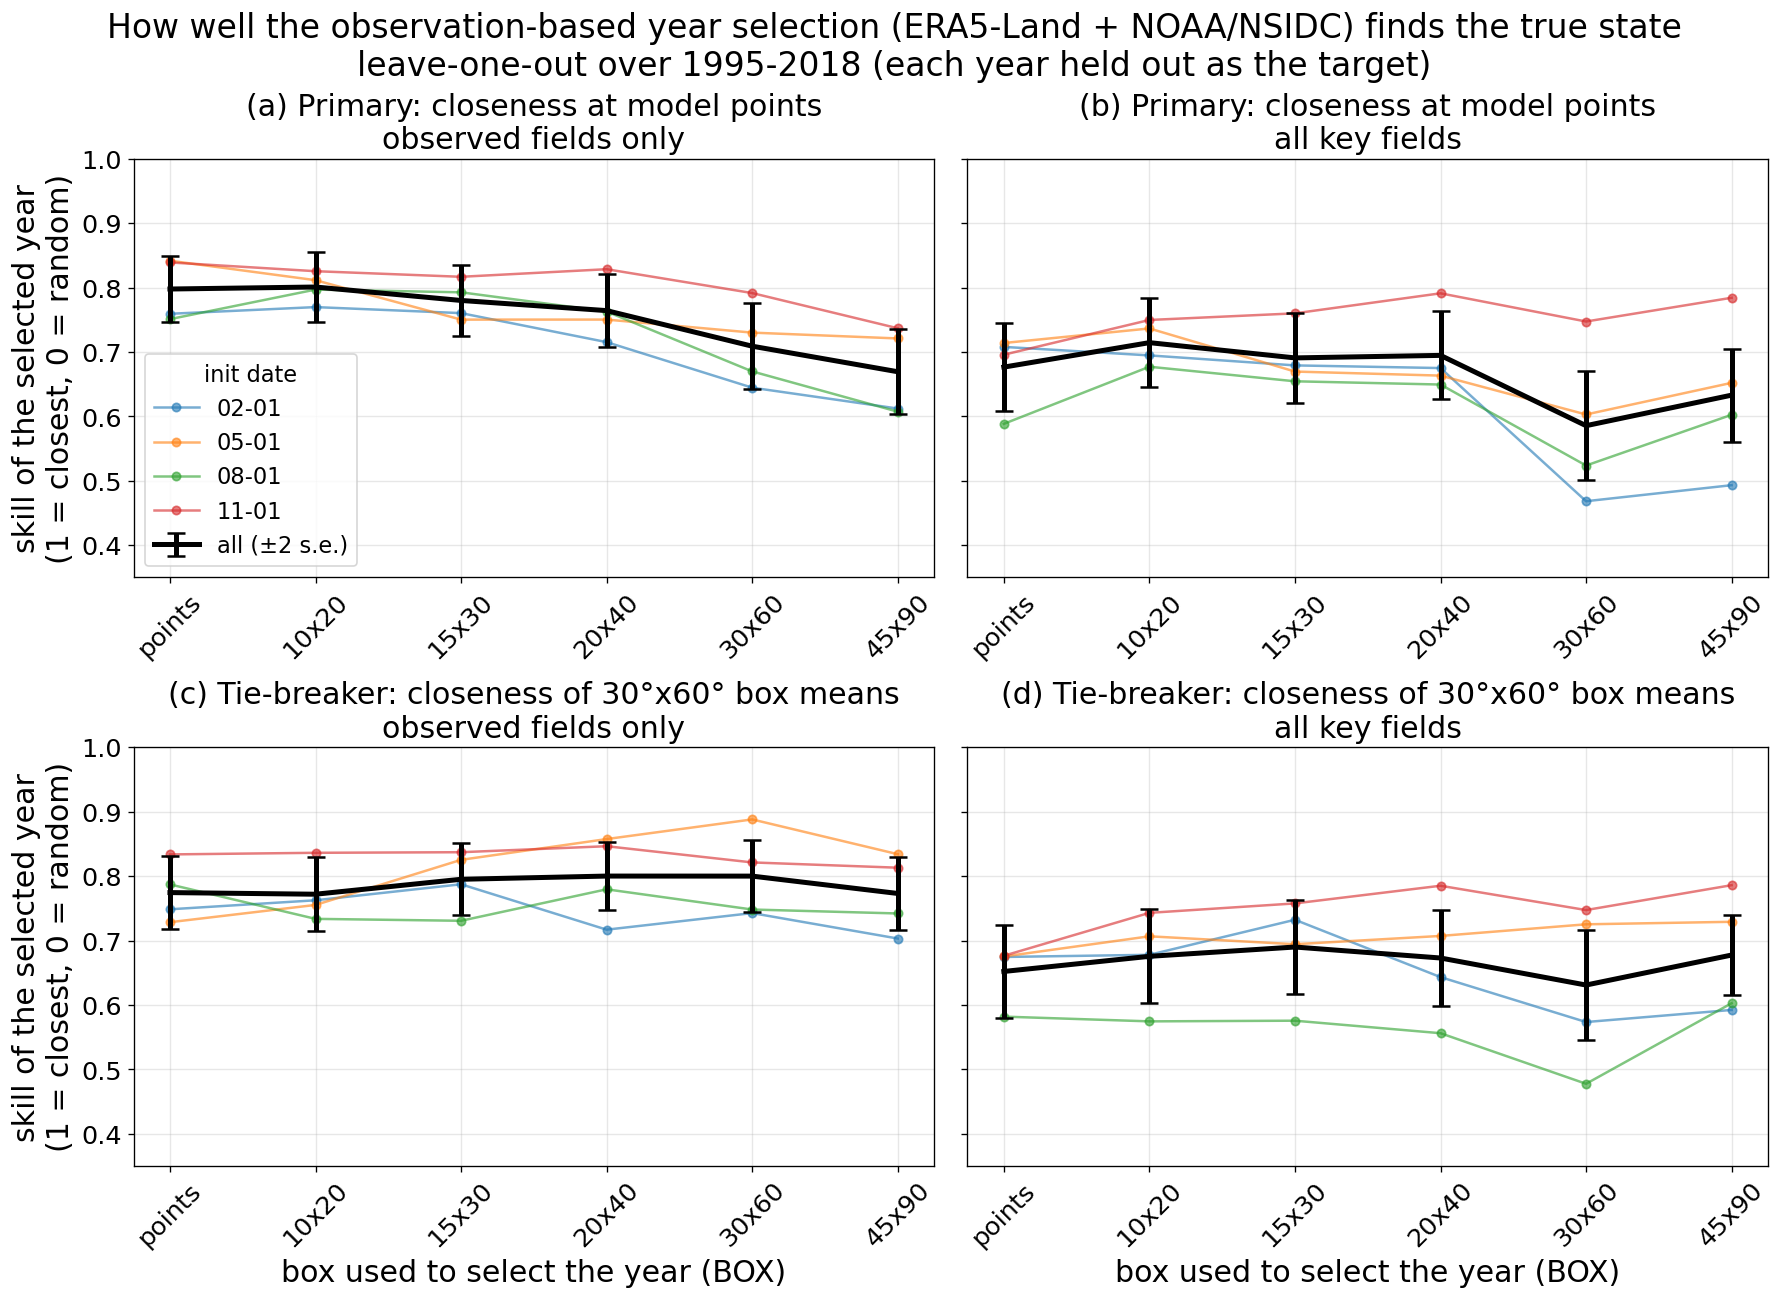

In [5]:
# ---- Figure parameters --------------------------------------------------------------
FONTSIZE    = 18              # base font size; other text scales from it
PANEL_SIZE  = (7.5, 5.5)      # width, height of one panel (inches)
LINE_WIDTH  = 1.5             # per-month lines (the all-month line is 2x)
MARKER_SIZE = 5
YLIM        = (0.35, 1.0)     # None for automatic
LEGEND_LOC  = "lower left"    # legend placed in panel (a)
SHOW_TITLE  = True            # overall figure title
FIG_NAME    = f"box_size_loo_skill_{RUN_TAG}.png"
FIG_DPI     = 200
ROW_TITLES = {"points": "Primary: closeness at model points",
              "30x60": "Tie-breaker: closeness of 30°x60° box means"}
COL_TITLES = {"observable": "observed fields only", "all": "all key fields"}
# ---------------------------------------------------------------------------------------

fs = {"title": FONTSIZE, "label": FONTSIZE, "tick": 0.85 * FONTSIZE,
      "legend": 0.75 * FONTSIZE, "suptitle": 1.1 * FONTSIZE}
rows_, cols_ = list(SCORES), list(box_loo.FIELD_SETS)
fig, axes = plt.subplots(len(rows_), len(cols_),
                         figsize=(PANEL_SIZE[0] * len(cols_), PANEL_SIZE[1] * len(rows_)),
                         sharey=True, squeeze=False)
x = np.arange(len(LABELS))
for r, scale in enumerate(rows_):
    for c, fset in enumerate(cols_):
        ax, key = axes[r, c], f"{scale},{fset}"
        table = box_loo.skill_table(loo, key, LABELS)
        for month in MONTHS:
            ax.plot(x, table[month], "o-", lw=LINE_WIDTH, ms=MARKER_SIZE, alpha=0.6, label=month)
        per_year = loo.pivot_table(index=["month", "year"], columns="box", values=f"skill[{key}]")[LABELS]
        se = per_year.std() / np.sqrt(len(per_year))
        ax.errorbar(x, table["all"], yerr=2 * se, color="k", lw=2 * LINE_WIDTH, ms=MARKER_SIZE,
                    capsize=0.3 * FONTSIZE, capthick=LINE_WIDTH, label="all (±2 s.e.)")
        ax.set_xticks(x, LABELS, rotation=45)
        ax.tick_params(labelsize=fs["tick"])
        if YLIM is not None:
            ax.set_ylim(*YLIM)
        ax.set_title(f"({'abcd'[r * len(cols_) + c]}) {ROW_TITLES.get(scale, scale)}\n"
                     f"{COL_TITLES.get(fset, fset)}", fontsize=fs["title"])
        ax.grid(alpha=0.3)
        if r == len(rows_) - 1:
            ax.set_xlabel("box used to select the year (BOX)", fontsize=fs["label"])
        if c == 0:
            ax.set_ylabel("skill of the selected year\n(1 = closest, 0 = random)", fontsize=fs["label"])
axes[0, 0].legend(title="init date", loc=LEGEND_LOC, fontsize=fs["legend"], title_fontsize=fs["legend"])
if SHOW_TITLE:
    fig.suptitle(f"How well the observation-based year selection (ERA5-Land + NOAA/NSIDC) finds the true state\n"
                 f"leave-one-out over {FIRST_YEAR}-{loo['year'].max()} (each year held out as the target)",
                 fontsize=fs["suptitle"])
fig.tight_layout()
if SAVE_DIAG:
    (DIAG_ROOT / "figure").mkdir(parents=True, exist_ok=True)
    fig_path = DIAG_ROOT / "figure" / FIG_NAME
    fig.savefig(fig_path, dpi=FIG_DPI, bbox_inches="tight")
    print(f"saved {fig_path}")
plt.show()

In [6]:
# Mean rank of the selected year among the candidates (1 = closest; a random pick is about half the candidates).
for key in KEYS:
    print(f"scored at {key}")
    display(loo.pivot_table(index="box", columns="month", values=f"rank[{key}]", aggfunc="mean")
            .loc[LABELS].assign(all=lambda t: t.mean(axis=1)).round(2))

scored at points,observable


month,02-01,05-01,08-01,11-01,all
box,,,,,
points,3.17,2.42,2.79,2.21,2.65
10x20,3.04,2.83,2.46,2.29,2.66
15x30,3.00,3.12,2.54,2.25,2.73
20x40,3.46,3.29,2.83,2.04,2.91
30x60,4.46,3.33,3.62,2.42,3.46
45x90,4.46,3.08,4.54,2.92,3.75


scored at points,all


month,02-01,05-01,08-01,11-01,all
box,,,,,
points,3.62,3.08,4.96,4.21,3.97
10x20,3.75,3.42,4.04,3.54,3.69
15x30,4.04,3.88,4.25,3.25,3.85
20x40,4.04,3.96,4.42,2.88,3.82
30x60,6.25,4.25,5.58,3.29,4.84
45x90,6.29,3.62,4.54,2.96,4.35


scored at 30x60,observable


month,02-01,05-01,08-01,11-01,all
box,,,,,
points,2.96,3.62,3.25,2.25,3.02
10x20,2.88,3.29,3.83,2.33,3.08
15x30,2.67,2.62,3.83,2.29,2.85
20x40,3.46,1.92,3.33,2.21,2.73
30x60,3.33,1.75,3.67,2.38,2.78
45x90,3.50,2.25,3.46,2.79,3.00


scored at 30x60,all


month,02-01,05-01,08-01,11-01,all
box,,,,,
points,3.71,4.17,4.96,4.17,4.25
10x20,3.67,3.92,5.12,3.58,4.07
15x30,3.29,3.96,5.12,3.42,3.95
20x40,4.17,3.88,5.42,3.21,4.17
30x60,5.04,3.88,6.12,3.46,4.62
45x90,4.75,3.42,4.38,3.00,3.89


## 3. Choice

1. **Primary (native grid):** keep the boxes whose skill at model points is within two standard
   errors (paired by held-out year) of the best box, for both the observed fields and all key fields.
2. **Tie-breaker (large scale):** among those, take the highest mean skill of the 30x60 box means.

In [7]:
CHOSEN, choice = box_loo.choose_box(loo, LABELS)
display(choice.round(3))
print(f"chosen box: {CHOSEN}")

,"skill [points,observable]","vs best [points,observable]","skill [points,all]","vs best [points,all]",tied with best on grid,large-scale skill (tie-breaker)
points,0.798,-0.003 ± 0.049,0.677,-0.038 ± 0.058,True,0.713
10x20,0.801,+0.000 ± 0.000,0.715,+0.000 ± 0.000,True,0.724
15x30,0.780,-0.021 ± 0.032,0.691,-0.024 ± 0.045,True,0.743
20x40,0.764,-0.037 ± 0.036,0.695,-0.020 ± 0.052,False,0.737
30x60,0.709,-0.092 ± 0.057,0.586,-0.129 ± 0.079,False,0.716
45x90,0.669,-0.132 ± 0.069,0.633,-0.082 ± 0.083,False,0.725


chosen box: 15x30


## 4. Conclusions

From the 1995-2018 test (24 held-out years per month; ERA5-Land and NOAA/NSIDC observations; five land
fields including subsurface soil temperature; box distances averaged over 4 placements of the box edges):

- **On the native grid, grid points, 10x20, and 15x30 are tied** (within two standard errors of the
  best, 10x20). Larger boxes are clearly worse.
- **Among the tied boxes, 15x30 matches the large-scale pattern best** (mean skill of the 30x60 box
  means 0.74, against 0.72 for 10x20 and 0.71 for grid points).
- **One box for all months.** Month-to-month differences are mostly within two standard errors;
  tuning the box per month would fit noise.
- **Edge placement matters.** With a single box grid, the choice was sensitive to where the box edges
  fell; averaging over 4 placements removes this and improves the selection for every box size.

`BOX = (15, 30)` with `BOX_SHIFTS = 4` is therefore used in 02-06. The 2015 test dates were not used
here, so the 2015 evaluation in 04-06 is independent of this choice.